<a href="https://colab.research.google.com/github/jppeirce/DSC210-Foundations-of-Data-Science/blob/main/Homework/HW07-supervised_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7: How Old Is This Abalone?

**DSC 210 Foundations of Data Science**

*Covers Module 11 (supervised learning: regression).*

```
ASK  ->  GET  ->  EXPLORE  ->  [ MODEL ]  ->  COMMUNICATE
```

References:
- Module 11 course notebook (linear regression, MAE / RMSE / $R^2$, residual plots, k-NN and tree regression, random forests, logistic regression, cross-validation)
- Abalone data: Nash, W. J., Sellers, T. L., Talbot, S. R., Cawthorn, A. J., and Ford, W. B. (1994). *The Population Biology of Abalone (Haliotis species) in Tasmania. I. Blacklip Abalone (H. rubra) from the North Coast and Islands of Bass Strait.* Sea Fisheries Division, Technical Report No. 48. Distributed through the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/1/abalone); this homework reads the copy at [github.com/jbrownlee/Datasets](https://github.com/jbrownlee/Datasets)

*Last major revision: 2026-11-08*

## Key Concepts

- Fit a line, and state its slope and intercept in the units of the problem
- Judge a regression with MAE, RMSE, $R^2$, a baseline, and a residual plot
- Compare a line with k-NN, a tree, and a random forest, and read feature importances
- Predict a probability with logistic regression, and find its decision boundary
- Compare models with cross-validation and choose one

## Instructions

**Total: 50 points.** Point values are listed with each problem.

- Cells marked `# RUN-TOGETHER` are complete; run them and read the output.
- Cells marked `# FILL-IN` contain blanks written as `____`.
- Cells marked `# ADAPT` are for you to write. Each one names a cell in the **Module 11 notebook**. Find that cell, copy it here, and change it to fit this problem (a different dataset, different columns, different names). Use the variable names the problem asks for, because later cells use them.
- Run the cells **in order**. Every figure must include a title and labeled axes.
- Most of the credit rides on your written answers. Quote specific numbers from your output.
- Submit the completed `.ipynb`, with all cells run and all figures visible, to Canvas.

---
## Part 0. Counting rings is slow (2 points)
---
<img src="https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/Homework/figures/abalone1.jpeg?raw=true" width="300">
<img src="https://raw.githubusercontent.com/jppeirce/DSC210-Foundations-of-Data-Science/main/Homework/figures/abalone2.jpeg?raw=true" width="300">

Abalone are large sea snails, harvested for food and closely managed by fisheries agencies. To find an abalone's age, a biologist cuts through the shell, stains it, and counts the growth **rings** under a microscope; the age in years is about the number of rings plus 1.5. That is slow, careful work.

A Tasmanian fisheries team measured 4,177 abalone in the early 1990s. **Can quick measurements (size and weight) predict the ring count, so fewer shells need to be cut?**

| Column | Meaning |
| --- | --- |
| `sex` | `M` male, `F` female, `I` infant (too young to tell) |
| `length`, `diameter`, `height` | shell size (mm) |
| `whole` | weight of the whole abalone (g) |
| `shucked` | weight of the meat (g) |
| `viscera` | gut weight (g) |
| `shell` | weight of the dried shell (g) |
| `rings` | **the label:** number of growth rings |

In [1]:
# RUN-TOGETHER  (setup)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/abalone.csv'
columns = ['sex', 'length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell', 'rings']
abalone = pd.read_csv(url, header=None, names=columns)    # the file has no header row

measurements = ['length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell']
abalone[measurements] = abalone[measurements] * 200       # the file stores every measurement divided by 200

print('shape:', abalone.shape)
abalone.describe().round(1)

shape: (4177, 9)


,length,diameter,height,whole,shucked,viscera,shell,rings
count,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0,4177.0
mean,104.8,81.6,27.9,165.7,71.9,36.1,47.8,9.9
std,24.0,19.8,8.4,98.1,44.4,21.9,27.8,3.2
min,15.0,11.0,0.0,0.4,0.2,0.1,0.3,1.0
25%,90.0,70.0,23.0,88.3,37.2,18.7,26.0,8.0
50%,109.0,85.0,28.0,159.9,67.2,34.2,46.8,9.0
75%,123.0,96.0,33.0,230.6,100.4,50.6,65.8,11.0
max,163.0,130.0,226.0,565.1,297.6,152.0,201.0,29.0


**Problem 0.** (2 points)

(a) What does one row of `abalone` represent? What is the mean number of rings?

(b) Look at the `min` and `max` of `height`. Which values are physically impossible for a shell whose longest side is at most 163 mm? Run the next cell, which removes rows with a height of 0 or of 60 mm or more, and report how many abalone remain.

**Your answer:**

(a) Each row of abalone represents a single abalone. Mean rings: 9.9

(b) The max of 226 is impossible. values above 163 are physically imposible. 4173 remain.

In [2]:
# RUN-TOGETHER  (Problem 0)
print('heights, smallest five:', abalone['height'].sort_values().head().round(1).tolist())
print('heights, largest five :', abalone['height'].sort_values().tail().round(1).tolist())

abalone = abalone[(abalone['height'] > 0) & (abalone['height'] < 60)].copy()
abalone['infant'] = (abalone['sex'] == 'I').astype(int)      # 1 for infants, 0 for adults
print('abalone kept:', len(abalone))

heights, smallest five: [0.0, 0.0, 2.0, 3.0, 3.0]
heights, largest five : [50.0, 50.0, 50.0, 103.0, 226.0]
abalone kept: 4173


---
## Part A. A line through the data (12 points)
---

### Problem A1. Fit the line (3 points)

**How many more rings does an abalone with a heavier shell tend to have?** Fit a line predicting `rings` from `shell`.

In [13]:
# ADAPT  (Problem A1)
# Module 11, Section 2.2: the RUN-TOGETHER cell that fits `lin` and prints the slope and intercept.
# Use X = abalone[['shell']] and y = abalone['rings'], with test_size=0.25 and random_state=210.
# Keep the names X_train, X_test, y_train, y_test, lin, and pred.
# Print the slope (rings per gram of shell), the intercept, and the observed range of shell.
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = abalone[['shell']]
y = abalone['rings']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=210)

lin = LinearRegression().fit(X_train, y_train)
pred = lin.predict(X_test)
print('slope    :', round(lin.coef_[0], 2), 'rings per g')
print('intercept:', round(lin.intercept_, 2), 'rings')

slope    : 0.07 rings per g
intercept: 6.49 rings


(a) Finish the sentence:
- *"Each additional 1 grams of shell is associated with about 0.07 more rings."*
- *"Each additional 10 grams of shell is associated with about 0.7 more rings."*

(b) The intercept describes an abalone whose shell weighs 0 g. The lightest shells in the data weigh about 0.3 g, so this is barely outside the data. Is 6.5 rings a believable age for the tiniest abalone?

(c) The line predicts about 28 rings for a 300 g shell. What is wrong with trusting that number.

**Your answer:**

(a)
- *"Each additional 1 grams of shell is associated with about 0.07 more rings."*
- *"Each additional 10 grams of shell is associated with about 0.7 more rings."*

(b)
- This is not believable, the model predicts the best fit for the data and does not predict low numbers accurately.

(c)The value 300g is well outside of our range of values. Predicting further than within our range will give innacurate predictions. We only know the best linear rate for the lower ranged data, and this could change as the range increases.

### Problem A2. How good is the line? (3 points)

In [ ]:
# ADAPT  (Problem A2)
# Module 11, Section 3: the RUN-TOGETHER cell that prints MAE, RMSE, R2, and the baseline MAE.
# Change the units in the printed labels from mpg to rings.

(a) Report MAE, RMSE, $R^2$, and the baseline MAE. By how many rings does the line improve on the baseline?

(b) The age is rings + 1.5 years. Translate the MAE into years. Would a fisheries manager be satisfied with that error for a single abalone? For the average of a whole catch?

**Your answer:**

(a)

(b)

### Problem A3. Read the residuals (3 points)

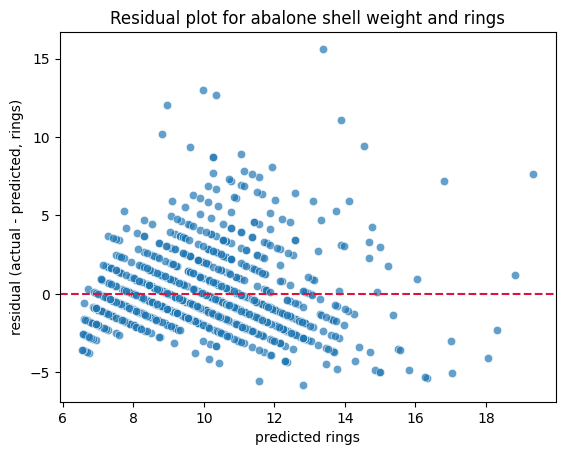

In [14]:
# ADAPT  (Problem A3)
# Module 11, Section 3: the RUN-TOGETHER cell that draws the residual plot.
# Change the axis labels and title to fit abalone.
resid = y_test - pred

sns.scatterplot(x=pred, y=resid, alpha=0.7)
plt.axhline(0, color='crimson', linestyle='--')
plt.xlabel('predicted rings'); plt.ylabel('residual (actual - predicted, rings)')
plt.title('Residual plot for abalone shell weight and rings')
plt.show()

In [15]:
# RUN-TOGETHER  (Problem A3): rings in shell-weight bands, all abalone
bands = pd.cut(abalone['shell'], [0, 10, 20, 40, 60, 80, 100, 210])
abalone.groupby(bands, observed=True)['rings'].agg(['mean', 'std', 'count']).round(2)

,mean,std,count
shell,,,
"(0, 10]",5.50,1.50,307
"(10, 20]",7.41,1.60,465
"(20, 40]",9.04,2.20,1019
"(40, 60]",10.56,2.67,1078
"(60, 80]",11.44,2.74,798
"(80, 100]",12.48,3.08,348
"(100, 210]",14.27,3.93,158


(a) Module 11, Section 3 shows three residual patterns: no pattern, a curve, and a fan. Which one is clearest in your plot, and what in the plot shows it? (The parallel diagonal stripes appear because ring counts are whole numbers; you can ignore them.)

(b) Use the `mean` column of the table to describe how rings grow with shell weight. Which second residual pattern does this suggest, and where does a straight line go wrong?

(c) Use the `std` column to explain the second pattern in biological terms: why might old abalone be harder to age from their weight?

**Your answer:**

(a) This plot shows fanning. This is shown by closer points lower predicted values and wider points with greater predicted values.

(b) As shell weight range increases, the values of the mean column increase. The residual pattern suggests error as it increases. The straight line prediction fails more and more as the shell weight increases and the residuals increase.

(c)The std shows that as they gain more shell weight, the predictions become more inacurate and each standard deviation increases. The residuals become wider and wider.

### Problem A4. Errors by hand (3 points)

Use the rounded line $\hat{y} = 6.5 + 0.07x$ for these four abalone, where $x$ is the shell weight in grams.

| abalone | shell $x$ (g) | actual rings | predicted | residual |
| --- | --- | --- | --- | --- |
| an infant | 5.0 | 4 | 6.85 | -2.85 |
| a female | 44.0 | 10 | 9.58 | 0.42 |
| a female | 91.0 | 12 | 12.87 | -0.87 |
| the oldest abalone in the data | 95.0 | 29 | 13.15 | 15.85 |

(a) Complete the table. Then compute the MAE and the RMSE of these four residuals. (Use Python as a calculator if you like.)

(b) What share of the **sum of absolute residuals** comes from the oldest abalone? What share of the **sum of squared residuals**? Which measure, MAE or RMSE, does one huge miss influence more, and why?

**Your answer:**

(a)MAE = (|-2.85|+|0.42|+|-0.87|+|15.85|)/4 = 5.00 ; RMSE = sqrt((|-2.85|^2+|0.42|^2+|-0.87|^2+|15.85|^2)/4) = 8.07

(b) sum of absolute residuals: 15.85/19.99(<- sum) = Oldest is 0.79; sum of squared residuals: 251.22/260.28(<- squared sum) = Oldes is 0.97; RMSE is more affected because large squared residuals can heavliy affect the overall value.


---
## Part B. Beyond a straight line (12 points)
---

### Problem B1. Let the model bend (4 points)

A3 showed the relationship bends. Models that do not assume a line might do better.

In [16]:
# ADAPT  (Problem B1)
# Part 1: Module 11, Section 4: the cell that fits KNeighborsRegressor for several k.
#         Use k = 1, 5, 25, 75. Keep the scaler step, and report MAE in rings and R2.
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler.transform(X_train), scaler.transform(X_test)

print(f"{'k':>4}  {'MAE (rings)':>10}  {'R2':>7}")
for k in (1, 5, 25, 75):
    knn = KNeighborsRegressor(n_neighbors=k).fit(Xtr_s, y_train)
    q = knn.predict(Xte_s)
    print(f'{k:>4}  {mean_absolute_error(y_test, q):>10.2f}  {r2_score(y_test, q):>7.3f}')
print(f"{'line':>4}  {mean_absolute_error(y_test, pred):>10.2f}  {r2_score(y_test, pred):>7.3f}")

   k  MAE (rings)       R2
   1        2.39   -0.175
   5        1.91    0.304
  25        1.78    0.423
  75        1.76    0.419
line        1.80    0.404


In [17]:
# Part 2: Module 11, Section 5.1: the cell that fits DecisionTreeRegressor for several depths.
#         Use max_depth = 1, 3, None, and print train R2 and test R2.
from sklearn.tree import DecisionTreeRegressor

for d in (1, 3, None):
    t = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_train, y_train)
    print(f'max_depth={str(d):9}  train R2={r2_score(y_train, t.predict(X_train)):.3f}   '
          f'test R2={r2_score(y_test, t.predict(X_test)):.3f}')

max_depth=1          train R2=0.279   test R2=0.285
max_depth=3          train R2=0.421   test R2=0.402
max_depth=None       train R2=0.587   test R2=0.344


(a) Which k-NN models beat the line on test $R^2$, and by how much? Given how curved the A3 table looked, is the gain large or small? Use the fan in A3 to suggest why no model can get much better using shell weight alone.

(b) What happens at `k = 1`, and what does a negative $R^2$ mean? What happens to the unlimited tree?

**Your answer:**

(a) k=25,75 beat the line test (0.404) by 0.019 and 0.015 respectively. This is quite small gain compared to the A3 table. One feature cannot correct the spread of the wide residuals that the fan produces.

(b) This is a sign of overfitting. Because k=1 is so low, the model is guessing worse than the normal. It overfits and hits every point exactly.

### Problem B2. More measurements (4 points)

This is Activity 11.2 with the abalone data.

In [19]:
# FILL-IN  (Problem B2)
FEATURES = ['length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell', 'infant']

for label, cols in [('one feature (shell weight)', ['shell']),
                    ('all eight features', FEATURES)]:
    Xa, Xb, ya, yb = train_test_split(abalone[cols], abalone['rings'], test_size=0.25, random_state=210)
    print(f'--- {label} ---')
    for name, model in [('linear', LinearRegression()),
                        ('tree, depth 3', DecisionTreeRegressor(max_depth=3, random_state=0)),
                        ('tree, unlimited', DecisionTreeRegressor(random_state=0)),
                        ('random forest', RandomForestRegressor(n_estimators=200, random_state=0))]:
        model.fit(Xa, ya)
        print(f'  {name:17} train R2={r2_score(ya, model.predict(Xa)):.3f}   '
              f'test R2={r2_score(yb, model.predict(Xb)):.3f}')
    print()

--- one feature (shell weight) ---
  linear            train R2=0.391   test R2=0.404
  tree, depth 3     train R2=0.421   test R2=0.402
  tree, unlimited   train R2=0.587   test R2=0.344
  random forest     train R2=0.577   test R2=0.383

--- all eight features ---
  linear            train R2=0.544   test R2=0.540
  tree, depth 3     train R2=0.439   test R2=0.390
  tree, unlimited   train R2=1.000   test R2=0.153
  random forest     train R2=0.937   test R2=0.542



Use a forest of 200 trees.

(a) With all eight features, rank the four models by test $R^2$. How much did the linear model gain over its one-feature version?

(b) In Module 11 (cars) the forest clearly beat the line once more features were added. Does it here? Use the training scores to describe what the forest is doing that the line is not, and whether it pays off.

**Your answer:**

(a) From the 8 feature test column,  tree, unlimited (worst),tree, depth 3, linear, random forest (best). The linear model gained 0.153 test and 0.136 train.

(b) The forest clearly beat the line yet again. the forest takes the trees predictions and finds the average to eliminate error. The linear model only guesses based on a line and does nothing to eliminate error. This forest pays off.

### Problem B3. Which measurements matter? (4 points)

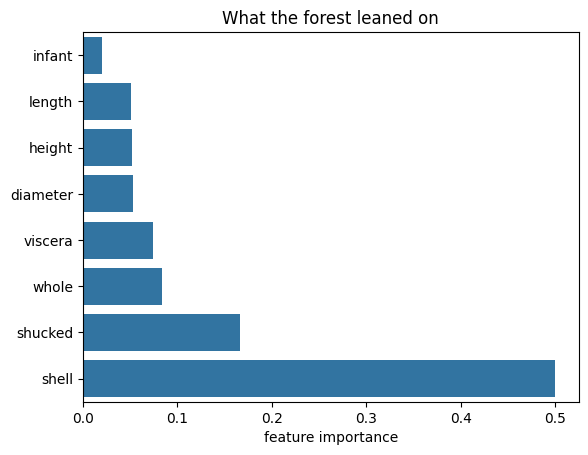

shell       0.500
shucked     0.166
whole       0.084
viscera     0.074
diameter    0.054
height      0.052
length      0.050
infant      0.020
dtype: float64


In [21]:
# ADAPT  (Problem B3)
# Module 11, Section 5.3: the RUN-TOGETHER cell that fits `rf` on all rows and plots feature importance.
# Use the features FEATURES and the label abalone['rings'].
from sklearn.ensemble import RandomForestRegressor
FEATURES = ['length', 'diameter', 'height', 'whole', 'shucked', 'viscera', 'shell', 'infant']

rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(abalone[FEATURES], abalone['rings'])

importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
sns.barplot(x=importance.values, y=importance.index, orient='h')
plt.xlabel('feature importance'); plt.ylabel('')
plt.title('What the forest leaned on')
plt.show()
print(importance.round(3).sort_values(ascending=False))

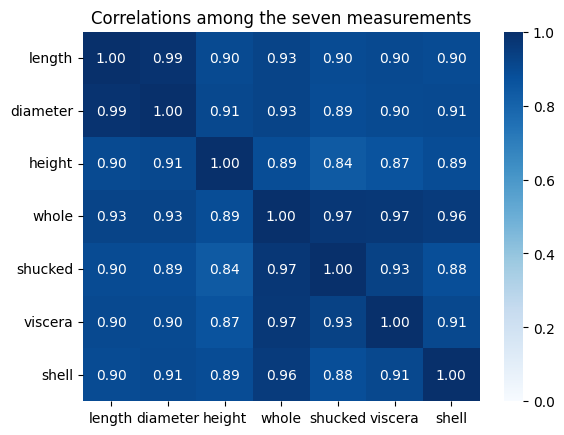

linear model coefficients (rings per unit):
length     -0.006
diameter    0.046
height      0.117
whole       0.044
shucked    -0.097
viscera    -0.056
shell       0.039
infant     -0.823
dtype: float64


In [22]:
# RUN-TOGETHER  (Problem B3)
sns.heatmap(abalone[measurements].corr(), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1)
plt.title('Correlations among the seven measurements')
plt.show()

lin_all = LinearRegression().fit(abalone[FEATURES], abalone['rings'])
print('linear model coefficients (rings per unit):')
print(pd.Series(lin_all.coef_, index=FEATURES).round(3))

(a) Which feature does the forest lean on most, and by how much over the next one? Use the correlation heatmap to explain why the other five size and weight measurements get small importances even though each one, alone, is strongly related to rings.

(b) The linear model's coefficient on `shucked` (meat weight) is **negative**. Does that mean that more meat makes an abalone younger? Explain using the heatmap.

**Your answer:**

(a) The forest leans on the shell weight the most. With a difference in significance of 0.334. This is a threefold increase. From the heatmap, we see they are all very correlated with eachother, so, when the model knows the shell weight, It already can tell a lot about the other features and it will already be able to predict rings fairly easily.

(b) All of the cofficents in the heatmap are very high, because of this, slighly lower coefficents will greatly stand out. This is just saying that the corelation is slighly lower than average and the statement, 'more meat makes an abalone younger' is false.

---
## Part C. Infant or adult? (8 points)
---

Infant abalone cannot yet be sexed, and fisheries rules generally aim to leave young animals in the water to grow. Can shell weight alone tell infants from adults? Here `infant` (1 or 0) is the label.

### Problem C1. Fit a logistic regression (4 points)

In [25]:
# ADAPT  (Problem C1)
# Module 11, Section 6.2: the RUN-TOGETHER cell that fits `log` on the Titanic data.
# Changes:
#   - the label is abalone['infant']; the only feature is ['shell']
#   - do NOT scale the feature this time, so the coefficient is per gram
#   - keep test_size=0.25, random_state=210, and stratify on the label
#   - print the test accuracy, the baseline (always predict "adult"), the intercept, and the coefficient
from sklearn.linear_model import LogisticRegression

d = abalone[['infant', 'shell']].dropna()

features = ['shell']
X = d[features]
y = d['infant']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                              random_state=210, stratify=y)
log = LogisticRegression(max_iter=2000).fit(X_train, y_train)

print('num of abalone:', d.shape[0])
print('test accuracy :', round(log.score(X_test, y_test), 3))
print('baseline      :', round(1 - y.mean(), 3), '(always predict died)')

print('intecept      :', round(log.intercept_[0], 3))
print()
for name, coef in zip(features, log.coef_[0]):
    print(f'  {name:>10}: {coef:+.2f}')

num of abalone: 4173
test accuracy : 0.789
baseline      : 0.679 (always predict died)
intecept      : 2.126

       shell: -0.07


(a) Report the test accuracy and the baseline. How much does the model add?

(b) The coefficient is negative. Say in words what that means for the chance that an abalone is an infant.

**Your answer:**

(a) test accuracy : 0.789 ;
baseline      : 0.679 (always predict died) ; The model adds 0.110 in accuracy.

(b) The coeeficent reports a negative corelation with the shell weight and being an infant. This means that as the shell gets heavier it is less likely to be an infant.

### Problem C2. Probabilities and the boundary, by hand (4 points)

Round the model to $z = 2.1 - 0.07\,x$, where $x$ is the shell weight in grams, and $p = \dfrac{1}{1 + e^{-z}}$ is the probability of being an infant. *(You will need $e^{-1.4} \approx 0.247$ and $e^{1.4} \approx 4.055$.)*

| shell $x$ (g) | $z$ | $p$ (infant) | predicted at 0.5 |
| --- | --- | --- | --- |
| 10 |  |  |  |
| 50 |  |  |  |

(a) Complete the table.

(b) Find the **decision boundary**: the shell weight where $p = 0.5$. Compare your two probabilities in the table, which sit the same distance from the boundary. What symmetry do you see?

(c) The fisheries team will use the model to decide which abalone to put back. Throwing back an adult loses one animal from the catch; keeping an infant harms the future population. Which mistake would they rather avoid, and should they move the threshold above or below 0.5 to do that?

**Your answer:**

(a)

(b)

(c)

---
## Part D. How much should we trust these scores? (5 points)
---

### Problem D1. Choose a model honestly (5 points)

Module 11, Section 7.2 compares models with cross-validation. Here, keep a **test set** aside, run the cross-validation on the **training** abalone only, choose one model, and only then score it once on the test set.

In [ ]:
# ADAPT  (Problem D2)
# Module 11, Section 7.2: the RUN-TOGETHER cell that compares three models with cross_val_score.
# Changes:
#   - first split: X8_train, X8_test, y8_train, y8_test = train_test_split(abalone[FEATURES], abalone['rings'],
#                                                                         test_size=0.25, random_state=210)
#   - run cross_val_score on X8_train and y8_train only (not on all the rows)
#   - then fit only the model you choose on the training abalone, name it `final`,
#     and print its R2 and MAE on X8_test

(a) Report the mean cross-validated $R^2$ of each model. Is the difference between the top two larger than the spread of their fold scores?

(b) Which model would you choose, and why? Give at least two reasons, one of them **not** about $R^2$.

(c) Report your chosen model's test $R^2$ and MAE. Why is this one test number more trustworthy than trying all three on the test set and keeping the best?

**Your answer:**

(a)

(b)

(c)

---
## Part E. Review and report (11 points)
---

### Problem E1. Choose the tool (9 points)

Imagine the fisheries team comes back with a larger survey. It has two tables:

**Abalone table**, one row per abalone, 40,000 rows:

| Column | Meaning |
| --- | --- |
| `site` | which of 40 collection sites it came from |
| the seven measurements | as in this homework (mm and g) |
| `sex` | `M`, `F`, or `I` |
| `rings` | ring count, recorded **only** for the 1 abalone in 10 whose shell was cut; blank for the rest |

**Site table**, one row per site and year, 40 sites over 10 years:

| Column | Meaning |
| --- | --- |
| `depth_m`, `water_temp_c` | average depth (m) and water temperature (degrees C) |
| `density` | abalone counted per square meter |
| `mean_rings` | average ring count of the abalone aged there that year |
| `closed_next_year` | whether the agency closed the site to harvest the following year (yes or no) |

For each question below, fill in one row of the table: is it **supervised** or **unsupervised**? If supervised, what is the **label** and is it a number or a category? Which **tool** from the Module 9, 10, or 11 toolkit tables would you use? Give **one reason** for your choice (more than one tool can be defensible).

1. Estimate the ring count of the 36,000 abalone whose shells were **not** cut.
2. The agency wants to know a year ahead which sites it will need to close. Using past years, predict `closed_next_year` for each site. Missing a site that should be closed is the worst mistake.
3. Are there a few natural kinds of site (for example, deep and cold vs shallow and warm)? Nobody has ever labeled the sites.
4. The seven measurements are close copies of one another. The team wants one or two numbers that summarize an abalone's size, so they can draw every abalone on a single scatterplot.

**Your answer:**

| Question | Supervised or unsupervised? | Label and its type (or "none") | Tool | One reason |
| --- | --- | --- | --- | --- |
| 1 |  |  |  |  |
| 2 |  |  |  |  |
| 3 |  |  |  |  |
| 4 |  |  |  |  |

### Problem E2. Report to the fisheries team (2 points)

In 3 to 4 sentences for biologists who have never fit a model: which model would you use to estimate ring counts from quick measurements, how far off should they expect it to be for a single abalone (in rings, then in years), and one honest caution, including whether they can stop cutting shells altogether.

**Your answer:**